# 2 — Data split


## Imports


In [16]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy import __version__ as scipy_version


## Configuration


In [17]:
from pathlib import Path
# ใช้ project root เดียวกัน ไม่ต้อง import โค้ด pipeline จาก program
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'dataset').is_dir() and (p / 'model').is_dir() and (p / 'program').is_dir())
RAW = ROOT / 'dataset/raw/mit-bih-arrhythmia-database-1.0.0'
DATA = ROOT / 'dataset/processed'
ARTIFACTS = ROOT / 'model/artifacts'
REPORTS = ROOT / 'model/reports'
CLASSES = ['N', 'S', 'V', 'F', 'Q']
SYMBOLS = ['NLRej', 'AaJS', 'VE', 'F', '/fQ']
LABEL_MAP = {s: i for i, group in enumerate(SYMBOLS) for s in group}
SEED = 42
PREPROCESSING = {'version': 1, 'fs': 360, 'left': 90, 'right': 162,
                 'band': [0.5, 40], 'order': 4, 'leads': ['MLII', 'V5']}

SPLIT_NAMES = ['train', 'validation', 'test']
SPLIT_TARGET = [0.8, 0.1, 0.1]
# Minimum annotation counts before window-boundary exclusions in preprocessing.
MIN_CLASS_COUNTS = {
    'train': {'N': 1, 'S': 1, 'V': 1, 'F': 500, 'Q': 500},
    'validation': {'N': 1, 'S': 1, 'V': 1, 'F': 20, 'Q': 500},
    'test': {'N': 1, 'S': 1, 'V': 1, 'F': 20, 'Q': 500},
}
SPLIT_TIME_LIMIT = 30.0


## Artifact helpers


In [18]:
def read_json(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'ไม่พบ {path}; กรุณารัน notebook ขั้นก่อนหน้าก่อน')
    return json.loads(path.read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def new_stage(marker):
    # ห้ามเขียนทับผลเดิมเงียบ ๆ เพราะอาจทำให้โมเดลอ้างอิงคนละ split
    if Path(marker).exists():
        raise FileExistsError(f'มีผลขั้นนี้แล้ว: {marker}; โหลดผลเดิมแทนการรันซ้ำ')
    if (ARTIFACTS / 'selection.json').exists():
        raise RuntimeError('ล็อกโมเดลแล้ว ไม่อนุญาตให้เตรียมข้อมูลหรือ tuning ใหม่ใน experiment เดิม')

## Patient leakage checks


In [19]:
def validate_split(beats, min_class_counts=None, expected_patients=None):
    if set(beats.split) != {'train', 'validation', 'test'}:
        raise ValueError('ต้องมีเพียง train/validation/test')
    if beats.groupby('patient_group').split.nunique().max() != 1:
        raise ValueError('พบ patient leakage')
    for name, part in beats.groupby('split'):
        if set(part.class_id) != set(range(5)):
            raise ValueError(f'{name} มีคลาสไม่ครบ 5; หยุดก่อนฝึก ห้ามแก้ split จากคะแนนโมเดล')
    paired = beats[beats.record_id.isin(['201', '202'])]
    if not paired.empty and (paired.patient_group.nunique() != 1 or paired.split.nunique() != 1):
        raise ValueError('201/202 ต้องเป็นผู้ป่วยกลุ่มเดียวและชุดเดียวกัน')
    if expected_patients is not None:
        observed = beats.groupby('split').patient_group.nunique().to_dict()
        if observed != expected_patients:
            raise ValueError(f'Unexpected patient counts: {observed}; expected {expected_patients}')
    if min_class_counts is not None:
        for split_name, minima in min_class_counts.items():
            observed = beats.loc[beats.split.eq(split_name), 'class_id'].value_counts()
            for label, minimum in minima.items():
                count = int(observed.get(CLASSES.index(label), 0))
                if count < minimum:
                    raise ValueError(f'{split_name}: minimum class support for {label} is {minimum}, got {count}')


## Load inventory


In [20]:
new_stage(DATA / 'split.json')
audit_info = read_json(DATA / 'audit.json')
if audit_info['unmapped_symbols']:
    raise ValueError(f"ตรวจ unmapped symbols ก่อน: {audit_info['unmapped_symbols']}")
beats = pd.read_parquet(DATA / 'inventory.parquet')
counts = pd.crosstab(beats.patient_group, beats.class_id).reindex(columns=range(5), fill_value=0)
groups = counts.index.to_numpy()
# 47 ผู้ป่วย -> 37/5/5 โดยไม่แยกคนเดียวกันข้ามชุด
n_holdout = max(1, round(len(groups) * .1))
patient_counts = dict(zip(SPLIT_NAMES, [len(groups) - 2 * n_holdout, n_holdout, n_holdout]))


## Constrained patient split

Require Q >= 500 and F >= 20 beats in both Validation and Test, while retaining at least 500 F and 500 Q in Train. Assign each patient to exactly one partition with 37/5/5 patients. Among feasible splits, minimize the mean absolute deviation of class allocations from 80/10/10. These support thresholds are protocol choices, not guarantees of statistical precision. No model scores are used.


In [21]:
def find_patient_split(counts, target, patient_counts, min_class_counts, time_limit=30.0):
    names = ['train', 'validation', 'test']
    values = counts.reindex(columns=range(len(CLASSES)), fill_value=0).to_numpy(dtype=float)
    n_groups, n_classes = values.shape
    target = np.asarray(target, dtype=float)
    quotas = np.array([patient_counts[name] for name in names], dtype=int)
    minimum = np.array([[min_class_counts.get(name, {}).get(label, 1)
                         for label in CLASSES] for name in names], dtype=int)
    totals = values.sum(axis=0)
    if target.shape != (3,) or (target <= 0).any() or not np.isclose(target.sum(), 1):
        raise ValueError('Split targets must be three positive proportions summing to one')
    if quotas.sum() != n_groups or (quotas <= 0).any():
        raise ValueError('Patient quotas must be positive and sum to all patient groups')
    if (values < 0).any() or (totals == 0).any() or (minimum < 1).any():
        raise ValueError('Counts must be nonnegative and every split must require all classes')
    if (minimum.sum(axis=0) > totals).any():
        raise ValueError('Infeasible minimum class support: insufficient total beats')

    # Binary x[split, patient]; continuous deviations measure class allocation error.
    n_assignments = 3 * n_groups
    n_variables = n_assignments + 3 * n_classes
    objective = np.r_[np.zeros(n_assignments), np.full(3 * n_classes, 1 / (3 * n_classes))]
    rows, lower, upper = [], [], []

    def add_constraint(row, low, high):
        rows.append(row)
        lower.append(low)
        upper.append(high)

    for patient in range(n_groups):
        row = np.zeros(n_variables)
        row[patient:n_assignments:n_groups] = 1
        add_constraint(row, 1, 1)
    for split_index in range(3):
        block = slice(split_index * n_groups, (split_index + 1) * n_groups)
        row = np.zeros(n_variables)
        row[block] = 1
        add_constraint(row, quotas[split_index], quotas[split_index])
        for class_index in range(n_classes):
            row = np.zeros(n_variables)
            row[block] = values[:, class_index]
            add_constraint(row, minimum[split_index, class_index], np.inf)
            deviation = n_assignments + split_index * n_classes + class_index
            for sign in [1, -1]:
                row = np.zeros(n_variables)
                row[block] = sign * values[:, class_index] / totals[class_index]
                row[deviation] = -1
                add_constraint(row, -np.inf, sign * target[split_index])

    result = milp(
        c=objective,
        integrality=np.r_[np.ones(n_assignments), np.zeros(3 * n_classes)],
        bounds=Bounds(np.zeros(n_variables), np.r_[np.ones(n_assignments), np.full(3 * n_classes, np.inf)]),
        constraints=LinearConstraint(np.asarray(rows), np.asarray(lower), np.asarray(upper)),
        options={'time_limit': float(time_limit), 'mip_rel_gap': 0.001},
    )
    if result.x is None:
        raise ValueError(f'No feasible patient split found; do not relax support silently. {result.message}')
    assignment = np.rint(result.x[:n_assignments]).astype(int).reshape(3, n_groups)
    if not np.allclose(assignment.ravel(), result.x[:n_assignments], atol=1e-5):
        raise ValueError('Solver returned a nonintegral patient assignment')
    actual = assignment @ values
    if not ((assignment.sum(axis=0) == 1).all()
            and np.array_equal(assignment.sum(axis=1), quotas)
            and (actual >= minimum).all()):
        raise ValueError('Solver assignment violates patient quotas or minimum class support')
    mapping = {str(patient): names[int(assignment[:, i].argmax())]
               for i, patient in enumerate(counts.index)}
    details = {
        'method': 'scipy.optimize.milp',
        'scipy_version': scipy_version,
        'objective': 'mean_absolute_class_allocation_error',
        'allocation_error': float(np.abs(actual / totals - target[:, None]).mean()),
        'status': int(result.status),
        'message': str(result.message),
        'optimal_within_tolerance': bool(result.success),
        'relative_gap': None if result.mip_gap is None else float(result.mip_gap),
        'relative_gap_tolerance': 0.001,
        'time_limit_seconds': float(time_limit),
    }
    return mapping, details

mapping, split_search = find_patient_split(
    counts, SPLIT_TARGET, patient_counts, MIN_CLASS_COUNTS, time_limit=SPLIT_TIME_LIMIT,
)
print(split_search['message'])
print(f"Mean absolute class allocation error: {split_search['allocation_error']:.4f}")


Optimization terminated successfully. (HiGHS Status 7: Optimal)
Mean absolute class allocation error: 0.0598


## Validate and save split


In [22]:
beats['split'] = beats.patient_group.map(mapping)
validate_split(beats, min_class_counts=MIN_CLASS_COUNTS, expected_patients=patient_counts)
manifest = {'target': SPLIT_TARGET, 'patient_split': mapping,
            'audit_hash': sha256(DATA / 'audit.json'),
            'patient_counts': patient_counts, 'minimum_class_counts': MIN_CLASS_COUNTS,
            'search': split_search,
            'record_split': dict(zip(beats.record_id, beats.split))}
manifest['split_hash'] = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()
beats.to_parquet(DATA / 'split_inventory.parquet', index=False)
write_json(DATA / 'split.json', manifest)
summary = beats.groupby('split').agg(patients=('patient_group', 'nunique'), beats=('beat_id', 'size'))
summary.join(pd.crosstab(beats.split, beats.class_id)).to_csv(DATA / 'split_summary.csv')
summary

,patients,beats
split,,
test,5,11628
train,37,85411
validation,5,12455


## Visualize the saved patient split

The target ratio is approximately 80% / 10% / 10%. Minimum class support takes priority over proximity to this target. Actual beat proportions differ because each patient group belongs to exactly one partition. These visualizations can be rerun after Imports and Configuration without repeating the split optimization.


In [23]:
split_order = ['train', 'validation', 'test']
split_labels = ['Train', 'Validation', 'Test']
split_colors = {'train': '#0072B2', 'validation': '#E69F00', 'test': '#009E73'}
class_colors = {'N': '#0072B2', 'S': '#E69F00', 'V': '#009E73',
                'F': '#CC79A7', 'Q': '#D55E00'}
split_counts = pd.read_csv(DATA / 'split_summary.csv', index_col='split').loc[split_order]
class_columns = [str(i) for i in range(len(CLASSES))]
split_overview = split_counts[['patients', 'beats']].copy()
split_overview['patient_share_pct'] = split_overview['patients'] / split_overview['patients'].sum() * 100
split_overview['beat_share_pct'] = split_overview['beats'] / split_overview['beats'].sum() * 100
split_overview = split_overview.join(split_counts[class_columns].rename(columns=dict(zip(class_columns, CLASSES))))
display(split_overview.style.format({
    **{column: '{:,}' for column in ['patients', 'beats', *CLASSES]},
    'patient_share_pct': '{:.2f}', 'beat_share_pct': '{:.2f}',
}))

saved_split = json.loads((DATA / 'split.json').read_text(encoding='utf-8'))
minimum_support = saved_split['minimum_class_counts']
support_table = pd.DataFrame({
    label: [minimum_support[name][label] for name in split_order]
    for label in CLASSES
}, index=split_order)
support_table.index.name = 'split'
print('Minimum required class counts (before preprocessing):')
display(support_table)
assert (split_overview[CLASSES] >= support_table).all().all()


,patients,beats,patient_share_pct,beat_share_pct,N,S,V,F,Q
split,,,,,,,,,
train,37,"85,411",78.72,78.01,"72,424","2,254","5,800",756,"4,177"
validation,5,"12,455",10.64,11.38,"9,719",248,664,22,"1,802"
test,5,"11,628",10.64,10.62,"8,488",279,772,25,"2,064"


Minimum required class counts (before preprocessing):


,N,S,V,F,Q
split,,,,,
train,1,1,1,500,500
validation,1,1,1,20,500
test,1,1,1,20,500


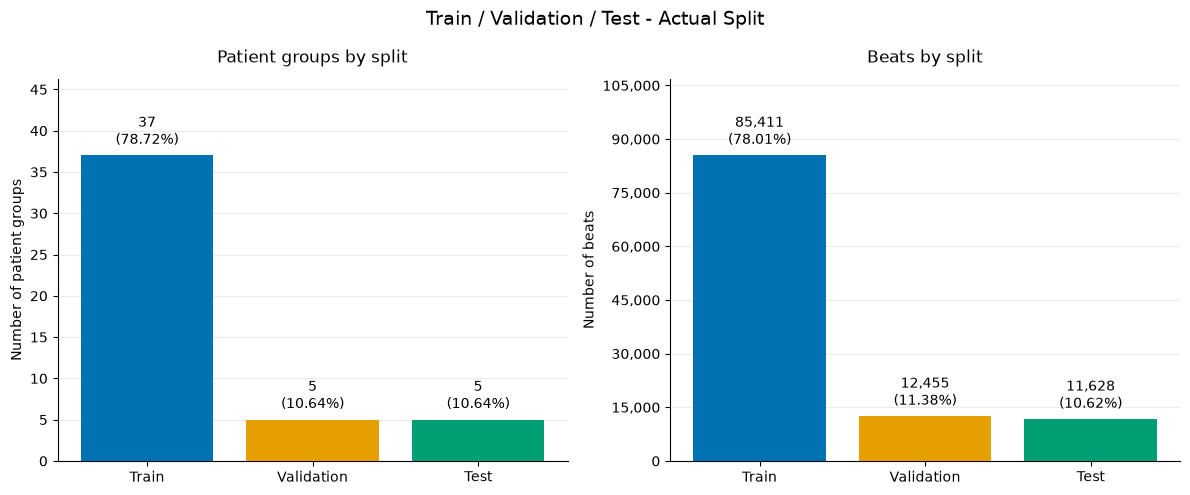

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, column, title, ylabel in zip(
    axes, ['patients', 'beats'], ['Patient groups by split', 'Beats by split'],
    ['Number of patient groups', 'Number of beats'],
):
    values = split_counts[column].to_numpy()
    shares = values / values.sum() * 100
    bars = ax.bar(split_labels, values,
                  color=[split_colors[name] for name in split_order], zorder=3)
    ax.bar_label(bars, labels=[f'{value:,}\n({share:.2f}%)'
                              for value, share in zip(values, shares)], padding=5)
    ax.set_title(title, pad=12)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(values.max() * 1.25, 1))
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.grid(axis='y', alpha=0.25, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Train / Validation / Test - Actual Split', fontsize=14)
fig.tight_layout()
plt.show()


### Allocation of each class across splits

Each panel uses its own y-axis scale to keep minority classes readable. Percentages are relative to the total of that class across all three partitions. Bar colors identify the partitions consistently with the overview above.


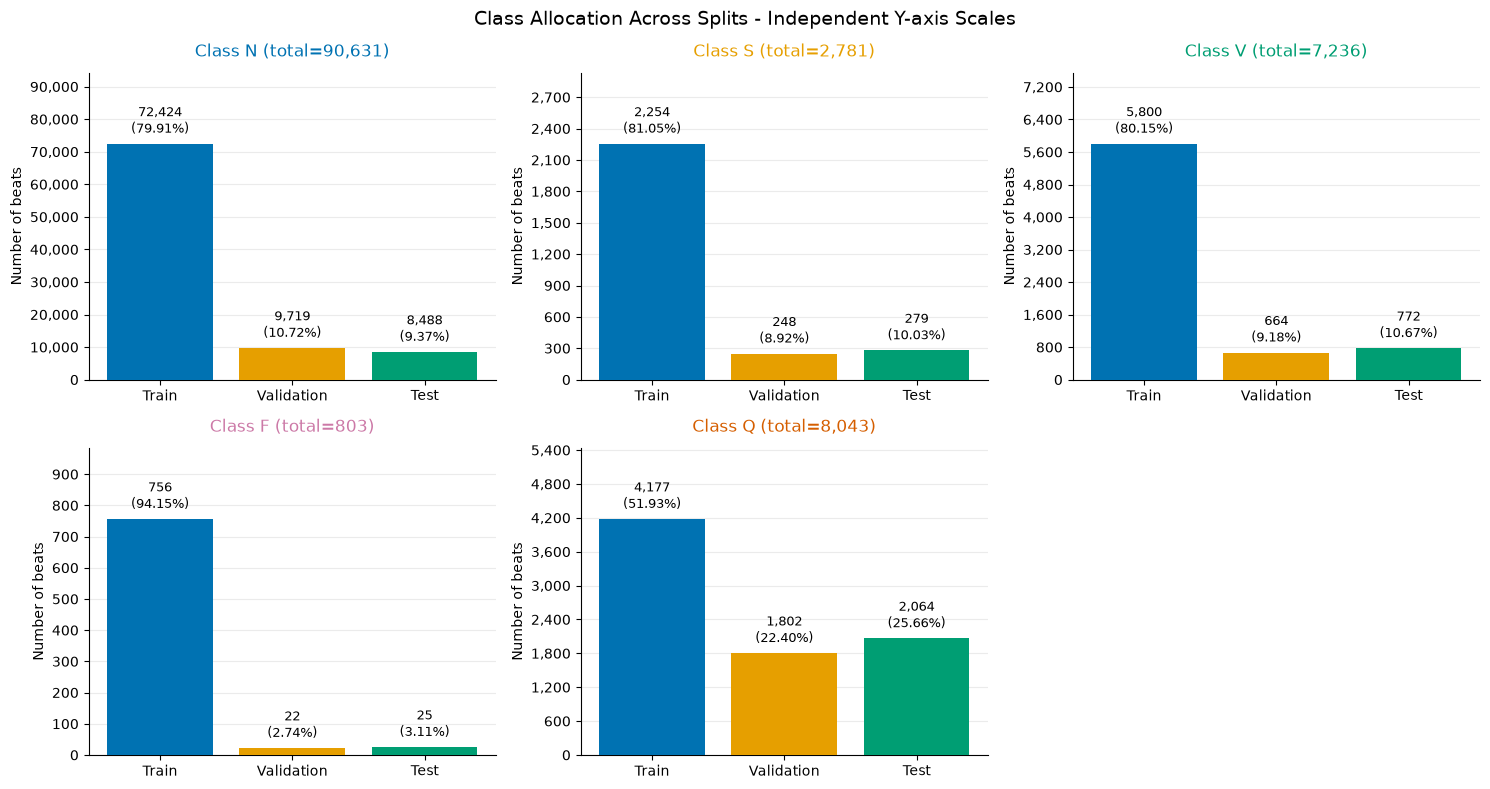

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column, label in zip(axes.flat, class_columns, CLASSES):
    values = split_counts[column].to_numpy()
    class_total = int(values.sum())
    shares = values / class_total * 100 if class_total else np.zeros(len(values))
    bars = ax.bar(split_labels, values,
                  color=[split_colors[name] for name in split_order], zorder=3)
    ax.bar_label(bars, labels=[f'{value:,}\n({share:.2f}%)'
                              for value, share in zip(values, shares)], padding=5, fontsize=9)
    ax.set_title(f'Class {label} (total={class_total:,})', color=class_colors[label], pad=12)
    ax.set_ylabel('Number of beats')
    ax.set_ylim(0, max(values.max() * 1.3, 1))
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.grid(axis='y', alpha=0.25, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)
for ax in list(axes.flat)[len(CLASSES):]:
    ax.set_visible(False)
fig.suptitle('Class Allocation Across Splits - Independent Y-axis Scales', fontsize=14)
fig.tight_layout()
plt.show()
